# Market Making Simulation: Naive vs Avellaneda–Stoikov
**BM, GBM, and covariance-aware multivariate diagnostics**

*Companion notebook — Starting Finance Club PoliTo*

---

## 1. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os, warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'figure.dpi': 120,
})

OUTPUT_DIR = r'C:\Users\salvm\Desktop\SF\HFT\1'

P = dict(
    S0        = 100.0,
    T         = 1.0,
    n_steps   = 1000,
    sigma_BM  = 1.5,
    mu_GBM    = 0.0,
    sigma_GBM = 0.015,   # calibrated so sigma_GBM*S0 = sigma_BM (equal dollar vol)
    gamma     = 0.1,
    k         = 1.5,
    A         = 140.0,
    N_MC      = 5000,
    seed      = 42,
)
P['dt'] = P['T'] / P['n_steps']

delta_opt = (1.0 / P['gamma']) * np.log(1.0 + P['gamma'] / P['k'])
print(f'Optimal half-spread delta* = {delta_opt:.4f}')
print(f'Time step          dt      = {P["dt"]:.4f}')

Optimal half-spread delta* = 0.6454
Time step          dt      = 0.0010


## 2. Mid-Price Dynamics

**ABM**: $dS_t = \sigma_{\mathrm{BM}}\,dW_t$

**GBM**: $dS_t = \sigma_{\mathrm{GBM}}\,S_t\,dW_t$ (zero drift for clarity)

In [2]:
def sim_BM(dW, S0, sigma):
    '''Arithmetic Brownian motion.'''
    S = np.empty(len(dW) + 1)
    S[0] = S0
    for i in range(len(dW)):
        S[i+1] = S[i] + sigma * dW[i]
    return S


def sim_GBM(dW, S0, mu, sigma, dt):
    '''Geometric Brownian motion (Euler-log scheme).'''
    S = np.empty(len(dW) + 1)
    S[0] = S0
    drift = (mu - 0.5 * sigma**2) * dt
    for i in range(len(dW)):
        S[i+1] = S[i] * np.exp(drift + sigma * dW[i])
    return S

## 3. Execution / Fill Model

$\lambda(\delta) = A\,e^{-k\delta}$, $P_{\text{fill}} = 1 - e^{-\lambda\,\Delta t}$

In [3]:
def fill_probs(S, p_bid, p_ask, A, k, dt):
    '''Per-step fill probabilities from exponential intensity model.'''
    lam_b = A * np.exp(-k * max(S - p_bid, 0.0))
    lam_a = A * np.exp(-k * max(p_ask - S,  0.0))
    return 1.0 - np.exp(-lam_b * dt), 1.0 - np.exp(-lam_a * dt)

## 4. Strategies

All quoting functions share signature `(S, q, t, **kw) -> (p_bid, p_ask)`.

**Naive**: $p^{b/a} = S \mp \delta^*$, $\delta^* = \frac{1}{\gamma}\ln\!\bigl(1+\frac{\gamma}{k}\bigr)$

**AS-BM**: $p^{b/a} = r \mp \delta^*$, $r = S - q\gamma\sigma_{\mathrm{BM}}^2(T-t)$

**AS-GBM**: same but $\sigma_{\mathrm{eff}} = \sigma_{\mathrm{GBM}}\cdot S$ (local vol)

In [4]:
def quote_naive(S, q, t, gamma, k, **_):
    delta = (1.0/gamma) * np.log(1.0 + gamma/k)
    return S - delta, S + delta


def quote_as_BM(S, q, t, gamma, k, sigma_BM, T, **_):
    tau   = max(T - t, 1e-9)
    r     = S - q * gamma * sigma_BM**2 * tau
    delta = (1.0/gamma) * np.log(1.0 + gamma/k)
    return r - delta, r + delta


def quote_as_GBM(S, q, t, gamma, k, sigma_GBM, T, **_):
    tau     = max(T - t, 1e-9)
    sig_eff = sigma_GBM * S
    r       = S - q * gamma * sig_eff**2 * tau
    delta   = (1.0/gamma) * np.log(1.0 + gamma/k)
    return r - delta, r + delta

In [5]:
def run_sim(t_arr, S, U_bid, U_ask, qfn, dt, **kw):
    '''
    Simulate one strategy on a fixed price path.
    kw must contain A and k (used by fill_probs); all kw forwarded to qfn.
    '''
    A = kw['A']; k = kw['k']
    n = len(S) - 1
    inv  = np.zeros(n+1)
    cash = np.zeros(n+1)
    pnl  = np.zeros(n+1)
    bids = np.zeros(n+1)
    asks = np.zeros(n+1)
    q, c = 0, 0.0
    for i in range(n):
        s = S[i]; t = t_arr[i]
        pb, pa = qfn(s, q, t, **kw)
        bids[i] = pb; asks[i] = pa
        pfb, pfa = fill_probs(s, pb, pa, A, k, dt)
        if U_bid[i] < pfb:
            q += 1;  c -= pb
        if U_ask[i] < pfa:
            q -= 1;  c += pa
        inv[i+1]  = q
        cash[i+1] = c
        pnl[i+1]  = c + q * S[i+1]
    pb, pa = qfn(S[-1], q, t_arr[-1], **kw)
    bids[-1] = pb; asks[-1] = pa
    return dict(inv=inv, cash=cash, pnl=pnl, bids=bids, asks=asks)

## 5. Single-Path Toy Example — Arithmetic Brownian Motion

In [6]:
rng   = np.random.default_rng(P['seed'])
dW_BM = rng.normal(0, np.sqrt(P['dt']), P['n_steps'])
Ub_BM = rng.random(P['n_steps'])
Ua_BM = rng.random(P['n_steps'])

t_arr = np.linspace(0, P['T'], P['n_steps']+1)
S_BM  = sim_BM(dW_BM, P['S0'], P['sigma_BM'])

# kw dicts include A and k so qfn and fill_probs share them via **kw
kw_naive  = dict(gamma=P['gamma'], k=P['k'], A=P['A'])
kw_as_bm  = dict(gamma=P['gamma'], k=P['k'], A=P['A'],
                 sigma_BM=P['sigma_BM'], T=P['T'])

r_naive_BM = run_sim(t_arr, S_BM, Ub_BM, Ua_BM, quote_naive, P['dt'], **kw_naive)
r_as_BM    = run_sim(t_arr, S_BM, Ub_BM, Ua_BM, quote_as_BM, P['dt'], **kw_as_bm)

print(f'BM | Naive  terminal PnL = {r_naive_BM["pnl"][-1]:+8.3f}'
      f'  terminal inv = {r_naive_BM["inv"][-1]:+5.0f}')
print(f'BM | AS     terminal PnL = {r_as_BM["pnl"][-1]:+8.3f}'
      f'  terminal inv = {r_as_BM["inv"][-1]:+5.0f}')

BM | Naive  terminal PnL =  +79.781  terminal inv =    -9
BM | AS     terminal PnL =  +63.240  terminal inv =    +4


## 6. Single-Path Toy Example — Geometric Brownian Motion

In [7]:
dW_GBM = rng.normal(0, np.sqrt(P['dt']), P['n_steps'])
Ub_GBM = rng.random(P['n_steps'])
Ua_GBM = rng.random(P['n_steps'])

S_GBM  = sim_GBM(dW_GBM, P['S0'], P['mu_GBM'], P['sigma_GBM'], P['dt'])

kw_as_gbm = dict(gamma=P['gamma'], k=P['k'], A=P['A'],
                 sigma_GBM=P['sigma_GBM'], T=P['T'])

r_naive_GBM = run_sim(t_arr, S_GBM, Ub_GBM, Ua_GBM, quote_naive,  P['dt'], **kw_naive)
r_as_GBM    = run_sim(t_arr, S_GBM, Ub_GBM, Ua_GBM, quote_as_GBM, P['dt'], **kw_as_gbm)

print(f'GBM | Naive  terminal PnL = {r_naive_GBM["pnl"][-1]:+8.3f}'
      f'  terminal inv = {r_naive_GBM["inv"][-1]:+5.0f}')
print(f'GBM | AS     terminal PnL = {r_as_GBM["pnl"][-1]:+8.3f}'
      f'  terminal inv = {r_as_GBM["inv"][-1]:+5.0f}')

GBM | Naive  terminal PnL =  +67.870  terminal inv =    -3
GBM | AS     terminal PnL =  +69.156  terminal inv =    -5


## 7. Covariance-Aware Multivariate Extension

The multivariate extension replaces scalar inventory risk with $q^\top\Sigma q$. The AS quote for asset $i$ reacts to the portfolio pressure $(\Sigma q)_i$, not only to the asset's own inventory.

In [8]:
def sim_multi_BM(dW, S0, chol_cov):
    '''Correlated arithmetic Brownian motion for d assets.'''
    n, d = dW.shape
    S = np.empty((n + 1, d))
    S[0] = np.asarray(S0, dtype=float)
    dS = dW @ chol_cov.T
    for i in range(n):
        S[i+1] = S[i] + dS[i]
    return S


def portfolio_risk_norm(q, Sigma):
    '''Instantaneous inventory risk sqrt(q.T Sigma q).'''
    q = np.asarray(q, dtype=float)
    return float(np.sqrt(max(q @ Sigma @ q, 0.0)))


def covariance_pressure(q, Sigma):
    '''Gradient direction of the quadratic inventory penalty.'''
    return Sigma @ np.asarray(q, dtype=float)


def fill_probs_multi(S, p_bid, p_ask, A, k, dt):
    '''Vectorized per-asset fill probabilities.'''
    S = np.asarray(S); p_bid = np.asarray(p_bid); p_ask = np.asarray(p_ask)
    A = np.asarray(A); k = np.asarray(k)
    lam_b = A * np.exp(-k * np.maximum(S - p_bid, 0.0))
    lam_a = A * np.exp(-k * np.maximum(p_ask - S, 0.0))
    return 1.0 - np.exp(-lam_b * dt), 1.0 - np.exp(-lam_a * dt)


def quote_naive_multi(S, q, t, gamma, k, **_):
    '''Independent symmetric quotes for each asset.'''
    S = np.asarray(S, dtype=float)
    delta = (1.0 / gamma) * np.log(1.0 + gamma / np.asarray(k))
    return S - delta, S + delta


def quote_as_multi_cov(S, q, t, gamma, k, Sigma, T, **_):
    '''
    Covariance-aware AS quotes.
    The center uses Sigma @ q; the bid/ask reservation prices include
    the +/- 0.5 * gamma * tau * diag(Sigma) marginal-risk correction.
    '''
    S = np.asarray(S, dtype=float)
    q = np.asarray(q, dtype=float)
    k = np.asarray(k, dtype=float)
    tau = max(T - t, 0.0)
    pressure = covariance_pressure(q, Sigma)
    risk_half = 0.5 * gamma * tau * np.diag(Sigma)
    liq_half = (1.0 / gamma) * np.log(1.0 + gamma / k)
    bid_res = S - gamma * tau * pressure - risk_half
    ask_res = S - gamma * tau * pressure + risk_half
    return bid_res - liq_half, ask_res + liq_half


def run_sim_multi(t_arr, S, U_bid, U_ask, qfn, dt, **kw):
    '''Portfolio accounting for a vector of assets and inventories.'''
    A = kw['A']; k = kw['k']
    n, d = S.shape[0] - 1, S.shape[1]
    inv = np.zeros((n + 1, d), dtype=int)
    cash = np.zeros(n + 1)
    pnl = np.zeros(n + 1)
    risk = np.zeros(n + 1)
    bids = np.zeros((n + 1, d))
    asks = np.zeros((n + 1, d))
    q = np.zeros(d, dtype=int)
    c = 0.0
    Sigma = kw.get('Sigma')
    for i in range(n):
        s = S[i]; t = t_arr[i]
        pb, pa = qfn(s, q, t, **kw)
        bids[i] = pb; asks[i] = pa
        pfb, pfa = fill_probs_multi(s, pb, pa, A, k, dt)
        bid_fill = U_bid[i] < pfb
        ask_fill = U_ask[i] < pfa
        q += bid_fill.astype(int)
        c -= float(np.sum(pb * bid_fill))
        q -= ask_fill.astype(int)
        c += float(np.sum(pa * ask_fill))
        inv[i+1] = q
        cash[i+1] = c
        pnl[i+1] = c + float(q @ S[i+1])
        if Sigma is not None:
            risk[i+1] = portfolio_risk_norm(q, Sigma)
    pb, pa = qfn(S[-1], q, t_arr[-1], **kw)
    bids[-1] = pb; asks[-1] = pa
    return dict(inv=inv, cash=cash, pnl=pnl, risk=risk, bids=bids, asks=asks)


def summarize_multi(res, Sigma):
    qT = res['inv'][-1].astype(float)
    return dict(
        pnl=float(res['pnl'][-1]),
        inv=qT,
        gross_abs_inv=float(np.sum(np.abs(qT))),
        risk_norm=portfolio_risk_norm(qT, Sigma),
        pressure=covariance_pressure(qT, Sigma),
    )

In [9]:
P_MULTI = dict(
    names=np.array(['Asset A', 'Asset B', 'Asset C']),
    S0=np.array([100.0, 75.0, 50.0]),
    sigma=np.array([1.50, 1.10, 0.90]),
    corr=np.array([[1.00, 0.65, -0.35],
                   [0.65, 1.00,  0.25],
                   [-0.35, 0.25, 1.00]]),
    A=np.array([140.0, 120.0, 100.0]),
    k=np.array([1.50, 1.80, 1.65]),
    N_MC=1000,
)
Sigma_multi = np.outer(P_MULTI['sigma'], P_MULTI['sigma']) * P_MULTI['corr']
chol_multi = np.linalg.cholesky(Sigma_multi)

d = len(P_MULTI['S0'])
rng_multi = np.random.default_rng(P['seed'] + 77)
dW_multi = rng_multi.normal(0, np.sqrt(P['dt']), (P['n_steps'], d))
Ub_multi = rng_multi.random((P['n_steps'], d))
Ua_multi = rng_multi.random((P['n_steps'], d))
S_multi = sim_multi_BM(dW_multi, P_MULTI['S0'], chol_multi)

kw_multi_naive = dict(gamma=P['gamma'], k=P_MULTI['k'], A=P_MULTI['A'])
kw_multi_as = dict(gamma=P['gamma'], k=P_MULTI['k'], A=P_MULTI['A'],
                   Sigma=Sigma_multi, T=P['T'])

r_multi_naive = run_sim_multi(t_arr, S_multi, Ub_multi, Ua_multi,
                              quote_naive_multi, P['dt'], **kw_multi_naive)
r_multi_as = run_sim_multi(t_arr, S_multi, Ub_multi, Ua_multi,
                           quote_as_multi_cov, P['dt'], **kw_multi_as)

sum_multi_naive = summarize_multi(r_multi_naive, Sigma_multi)
sum_multi_as = summarize_multi(r_multi_as, Sigma_multi)

print('Multivariate covariance matrix:')
print(Sigma_multi)
for label, out in [('Naive', sum_multi_naive), ('AS-cov', sum_multi_as)]:
    print(f'Multi | {label:<6} terminal PnL = {out["pnl"]:+8.3f}'
          f'  gross |q| = {out["gross_abs_inv"]:5.1f}'
          f'  risk norm = {out["risk_norm"]:6.3f}')
    print(f'        terminal inv      = {out["inv"]}')
    print(f'        Sigma @ q pressure = {out["pressure"]}')

q_demo = np.array([8, 0, -5])
pb_demo, pa_demo = quote_as_multi_cov(P_MULTI['S0'], q_demo, 0.0,
                                      gamma=P['gamma'], k=P_MULTI['k'],
                                      Sigma=Sigma_multi, T=P['T'], A=P_MULTI['A'])
print('\nDemo inventory q =', q_demo)
print('Covariance pressure Sigma @ q =', covariance_pressure(q_demo, Sigma_multi))
print('AS-cov bid quotes =', pb_demo)
print('AS-cov ask quotes =', pa_demo)

Multivariate covariance matrix:
[[ 2.25    1.0725 -0.4725]
 [ 1.0725  1.21    0.2475]
 [-0.4725  0.2475  0.81  ]]
Multi | Naive  terminal PnL = +150.556  gross |q| =  27.0  risk norm = 20.507
        terminal inv      = [  1. -14. -12.]
        Sigma @ q pressure = [ -7.095  -18.8375 -13.6575]
Multi | AS-cov terminal PnL = +148.849  gross |q| =   1.0  risk norm =  1.500
        terminal inv      = [1. 0. 0.]
        Sigma @ q pressure = [ 2.25    1.0725 -0.4725]

Demo inventory q = [ 8  0 -5]
Covariance pressure Sigma @ q = [20.3625  7.3425 -7.83  ]
AS-cov bid quotes = [97.20586479 73.66457779 50.154095  ]
AS-cov ask quotes = [98.72163521 74.86692221 51.411905  ]


In [10]:
def mc_compare_multi(P, P_MULTI, Sigma, chol_cov, seed_base=3000):
    N = P_MULTI['N_MC']; n = P['n_steps']; d = len(P_MULTI['S0'])
    t_arr = np.linspace(0, P['T'], n + 1)
    master = np.random.default_rng(seed_base)
    dW_all = master.normal(0, np.sqrt(P['dt']), (N, n, d))
    Ub_all = master.random((N, n, d))
    Ua_all = master.random((N, n, d))
    pnl_n = np.zeros(N); pnl_as = np.zeros(N)
    gross_n = np.zeros(N); gross_as = np.zeros(N)
    risk_n = np.zeros(N); risk_as = np.zeros(N)
    for m in range(N):
        S = sim_multi_BM(dW_all[m], P_MULTI['S0'], chol_cov)
        rn = run_sim_multi(t_arr, S, Ub_all[m], Ua_all[m],
                           quote_naive_multi, P['dt'], **kw_multi_naive)
        ra = run_sim_multi(t_arr, S, Ub_all[m], Ua_all[m],
                           quote_as_multi_cov, P['dt'], **kw_multi_as)
        sn = summarize_multi(rn, Sigma)
        sa = summarize_multi(ra, Sigma)
        pnl_n[m] = sn['pnl']; pnl_as[m] = sa['pnl']
        gross_n[m] = sn['gross_abs_inv']; gross_as[m] = sa['gross_abs_inv']
        risk_n[m] = sn['risk_norm']; risk_as[m] = sa['risk_norm']
    return dict(pnl_n=pnl_n, pnl_as=pnl_as,
                gross_n=gross_n, gross_as=gross_as,
                risk_n=risk_n, risk_as=risk_as)


print(f'Running multivariate diagnostic MC ({P_MULTI["N_MC"]} paths) ...')
mc_MULTI = mc_compare_multi(P, P_MULTI, Sigma_multi, chol_multi)
print('Multivariate MC done.')

print(f'{"Metric":<28} {"Naive":>12} {"AS-cov":>12}')
print('-'*54)
for label, a, b in [
    ('Mean terminal PnL', np.mean(mc_MULTI['pnl_n']), np.mean(mc_MULTI['pnl_as'])),
    ('Std terminal PnL', np.std(mc_MULTI['pnl_n']), np.std(mc_MULTI['pnl_as'])),
    ('Mean gross |q_T|', np.mean(mc_MULTI['gross_n']), np.mean(mc_MULTI['gross_as'])),
    ('Mean risk norm', np.mean(mc_MULTI['risk_n']), np.mean(mc_MULTI['risk_as'])),
]:
    print(f'{label:<28} {a:>12.3f} {b:>12.3f}')

Running multivariate diagnostic MC (1000 paths) ...


Multivariate MC done.
Metric                              Naive       AS-cov
------------------------------------------------------
Mean terminal PnL                 158.221      154.594
Std terminal PnL                   17.034       10.690
Mean gross |q_T|                   21.784       11.693
Mean risk norm                     16.846        7.196


## 8. Monte Carlo Comparison

N = 5,000 paths per dynamics.

In [11]:
def mc_compare(sim_fn, qfn_naive, qfn_as, kw_naive, kw_as, P, seed_base):
    N = P['N_MC']; n = P['n_steps']
    t_arr = np.linspace(0, P['T'], n+1)
    master = np.random.default_rng(seed_base)
    dW_all = master.normal(0, np.sqrt(P['dt']), (N, n))
    Ub_all = master.random((N, n))
    Ua_all = master.random((N, n))
    pnl_n  = np.zeros(N); pnl_as  = np.zeros(N)
    inv_n  = np.zeros(N); inv_as  = np.zeros(N)
    for m in range(N):
        S  = sim_fn(dW_all[m])
        Ub = Ub_all[m]; Ua = Ua_all[m]
        rn = run_sim(t_arr, S, Ub, Ua, qfn_naive, P['dt'], **kw_naive)
        ra = run_sim(t_arr, S, Ub, Ua, qfn_as,    P['dt'], **kw_as)
        pnl_n[m]  = rn['pnl'][-1];  inv_n[m]  = rn['inv'][-1]
        pnl_as[m] = ra['pnl'][-1];  inv_as[m] = ra['inv'][-1]
    return dict(pnl_n=pnl_n, pnl_as=pnl_as, inv_n=inv_n, inv_as=inv_as)

In [12]:
print(f'Running BM Monte Carlo ({P["N_MC"]} paths) ...')
mc_BM = mc_compare(
    sim_fn    = lambda dW: sim_BM(dW, P['S0'], P['sigma_BM']),
    qfn_naive = quote_naive,
    qfn_as    = quote_as_BM,
    kw_naive  = kw_naive,
    kw_as     = kw_as_bm,
    P         = P,
    seed_base = 1000,
)
print('BM MC done.')

Running BM Monte Carlo (5000 paths) ...


BM MC done.


In [13]:
print(f'Running GBM Monte Carlo ({P["N_MC"]} paths) ...')
mc_GBM = mc_compare(
    sim_fn    = lambda dW: sim_GBM(dW, P['S0'], P['mu_GBM'], P['sigma_GBM'], P['dt']),
    qfn_naive = quote_naive,
    qfn_as    = quote_as_GBM,
    kw_naive  = kw_naive,
    kw_as     = kw_as_gbm,
    P         = P,
    seed_base = 2000,
)
print('GBM MC done.')

Running GBM Monte Carlo (5000 paths) ...


GBM MC done.


In [14]:
def stats(pnl, inv):
    mu = np.mean(pnl); sd = np.std(pnl)
    return dict(mean_pnl=mu, std_pnl=sd,
                mean_absinv=np.mean(np.abs(inv)),
                sharpe=mu/(sd+1e-12))

st = {
    'BM_Naive' : stats(mc_BM['pnl_n'],   mc_BM['inv_n']),
    'BM_AS'    : stats(mc_BM['pnl_as'],  mc_BM['inv_as']),
    'GBM_Naive': stats(mc_GBM['pnl_n'],  mc_GBM['inv_n']),
    'GBM_AS'   : stats(mc_GBM['pnl_as'], mc_GBM['inv_as']),
}
cols = ['BM_Naive','BM_AS','GBM_Naive','GBM_AS']
print(f'{"Metric":<26} {"BM Naive":>10} {"BM AS":>10} {"GBM Naive":>10} {"GBM AS":>10}')
print('-'*68)
for metric, label in [
    ('mean_pnl',    'Mean terminal PnL'),
    ('std_pnl',     'Std terminal PnL'),
    ('mean_absinv', 'Mean |terminal inv|'),
    ('sharpe',      'Sharpe-like ratio'),
]:
    v = [st[c][metric] for c in cols]
    print(f'{label:<26} {v[0]:>10.3f} {v[1]:>10.3f} {v[2]:>10.3f} {v[3]:>10.3f}')
print()
print('=== LaTeX rows ===')
for metric, label in [
    ('mean_pnl',    'Mean terminal PnL'),
    ('std_pnl',     'Std terminal PnL'),
    ('mean_absinv', r'Mean $|q_T|$'),
    ('sharpe',      'Sharpe-like ratio'),
]:
    v = [st[c][metric] for c in cols]
    print(f'{label} & {v[0]:.3f} & {v[1]:.3f} & {v[2]:.3f} & {v[3]:.3f} \\\\')

Metric                       BM Naive      BM AS  GBM Naive     GBM AS
--------------------------------------------------------------------
Mean terminal PnL              67.145     63.930     67.109     63.894
Std terminal PnL               12.178      6.680     12.316      6.718
Mean |terminal inv|             7.817      3.116      7.897      3.095
Sharpe-like ratio               5.514      9.570      5.449      9.511

=== LaTeX rows ===
Mean terminal PnL & 67.145 & 63.930 & 67.109 & 63.894 \\
Std terminal PnL & 12.178 & 6.680 & 12.316 & 6.718 \\
Mean $|q_T|$ & 7.817 & 3.116 & 7.897 & 3.095 \\
Sharpe-like ratio & 5.514 & 9.570 & 5.449 & 9.511 \\


## 9. Figure Export

`py1.png` — BM case, `py2.png` — GBM case

In [15]:
COLORS = dict(mid='#2b2b2b', naive='#4878CF', AS='#C44E52')

def make_figure(t_arr, S, r_naive, r_as, mc_res, label, filename):
    '''2x2 comparison figure: quotes | inventory / PnL | terminal dist.'''
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    fig.suptitle(f'Naive vs AS Market Making  —  {label}',
                 fontsize=13, fontweight='bold')

    ax = axes[0,0]
    ax.plot(t_arr, S,              color=COLORS['mid'],   lw=1.2, label='Mid-price')
    ax.plot(t_arr, r_naive['bids'],color=COLORS['naive'], lw=0.9, ls='--', alpha=0.75, label='Naive bid/ask')
    ax.plot(t_arr, r_naive['asks'],color=COLORS['naive'], lw=0.9, ls='--', alpha=0.75)
    ax.plot(t_arr, r_as['bids'],   color=COLORS['AS'],    lw=0.9, ls='-.', alpha=0.75, label='AS bid/ask')
    ax.plot(t_arr, r_as['asks'],   color=COLORS['AS'],    lw=0.9, ls='-.', alpha=0.75)
    ax.set_xlabel('Time $t$'); ax.set_ylabel('Price')
    ax.set_title('(a) Mid-Price and Quotes'); ax.legend(fontsize=9)

    ax = axes[0,1]
    ax.plot(t_arr, r_naive['inv'], color=COLORS['naive'], lw=1.1, label='Naive')
    ax.plot(t_arr, r_as['inv'],    color=COLORS['AS'],    lw=1.1, ls='--', label='AS')
    ax.axhline(0, color='gray', lw=0.7, ls=':', alpha=0.6)
    ax.fill_between(t_arr, r_naive['inv'], 0, color=COLORS['naive'], alpha=0.07)
    ax.fill_between(t_arr, r_as['inv'],    0, color=COLORS['AS'],    alpha=0.07)
    ax.set_xlabel('Time $t$'); ax.set_ylabel('Inventory $q_t$')
    ax.set_title('(b) Inventory Path'); ax.legend(fontsize=9)

    ax = axes[1,0]
    ax.plot(t_arr, r_naive['pnl'], color=COLORS['naive'], lw=1.1, label='Naive')
    ax.plot(t_arr, r_as['pnl'],    color=COLORS['AS'],    lw=1.1, ls='--', label='AS')
    ax.axhline(0, color='gray', lw=0.7, ls=':', alpha=0.6)
    ax.set_xlabel('Time $t$'); ax.set_ylabel(r'PnL $W_t = X_t + q_t S_t$')
    ax.set_title('(c) Mark-to-Market PnL'); ax.legend(fontsize=9)

    ax = axes[1,1]
    all_v = np.concatenate([mc_res['pnl_n'], mc_res['pnl_as']])
    lo, hi = np.percentile(all_v,1), np.percentile(all_v,99)
    bins = np.linspace(lo, hi, 60)
    ax.hist(mc_res['pnl_n'],  bins=bins, color=COLORS['naive'], alpha=0.50, density=True, label='Naive')
    ax.hist(mc_res['pnl_as'], bins=bins, color=COLORS['AS'],    alpha=0.50, density=True, label='AS')
    ax.axvline(np.mean(mc_res['pnl_n']),  color=COLORS['naive'], lw=1.5, ls='--')
    ax.axvline(np.mean(mc_res['pnl_as']), color=COLORS['AS'],    lw=1.5, ls='--')
    ax.set_xlabel('Terminal PnL $W_T$'); ax.set_ylabel('Density')
    ax.set_title(f'(d) Terminal PnL ({P["N_MC"]:,} MC paths)'); ax.legend(fontsize=9)

    fig.tight_layout(rect=[0,0,1,0.94])
    path = os.path.join(OUTPUT_DIR, filename)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {path}')
    return fig

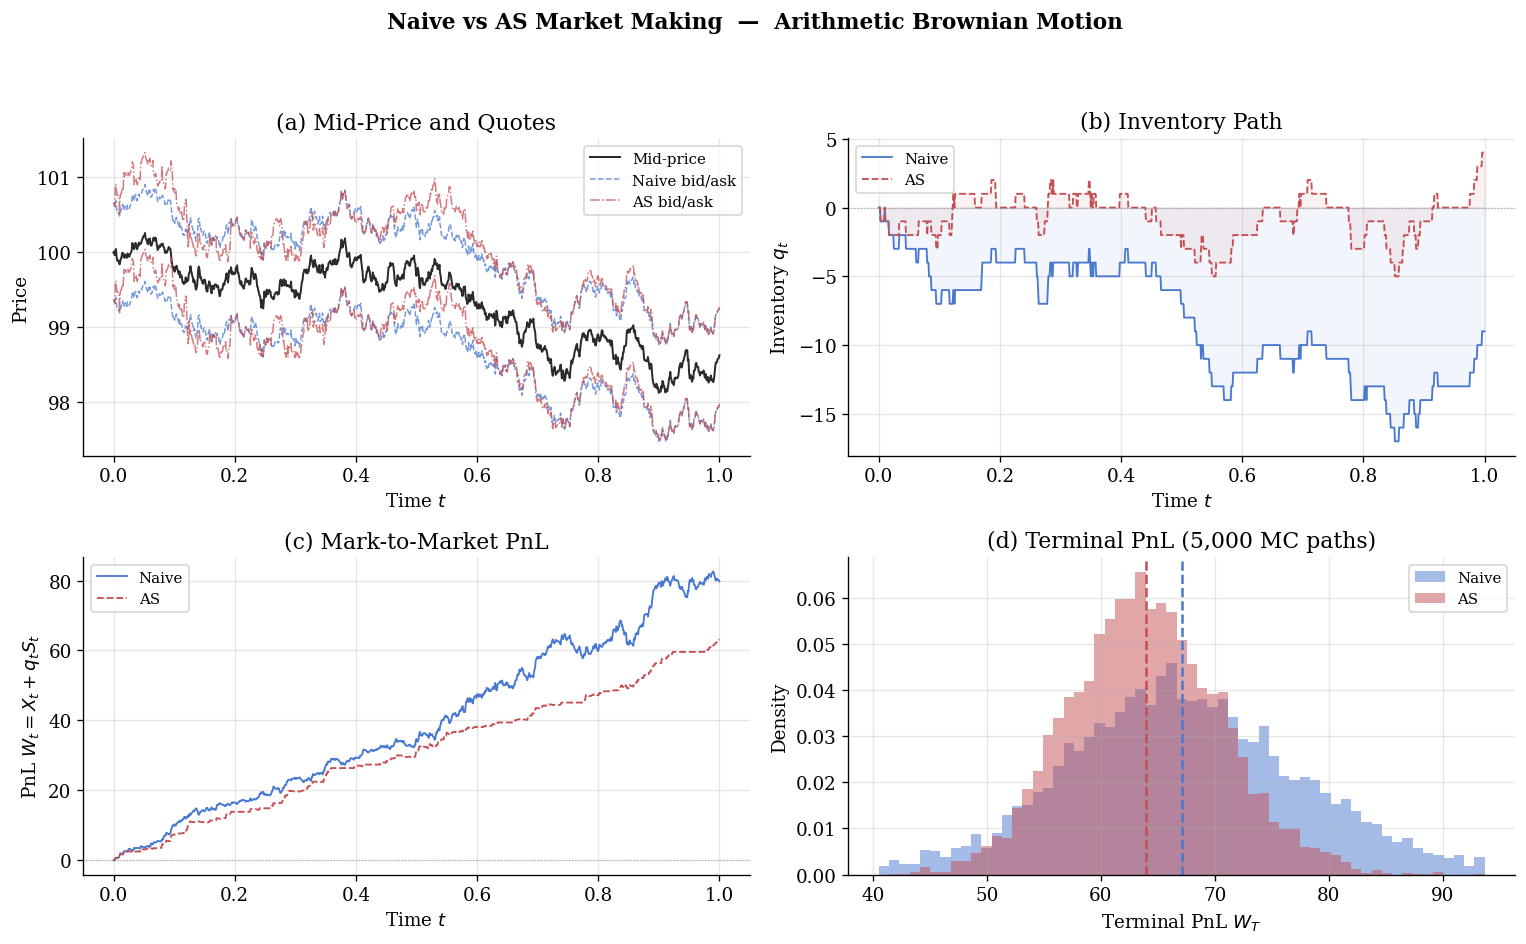

Saved: C:\Users\salvm\Desktop\SF\HFT\1\py1.png


In [16]:
fig1 = make_figure(t_arr, S_BM, r_naive_BM, r_as_BM, mc_BM,
                   label='Arithmetic Brownian Motion', filename='py1.png')

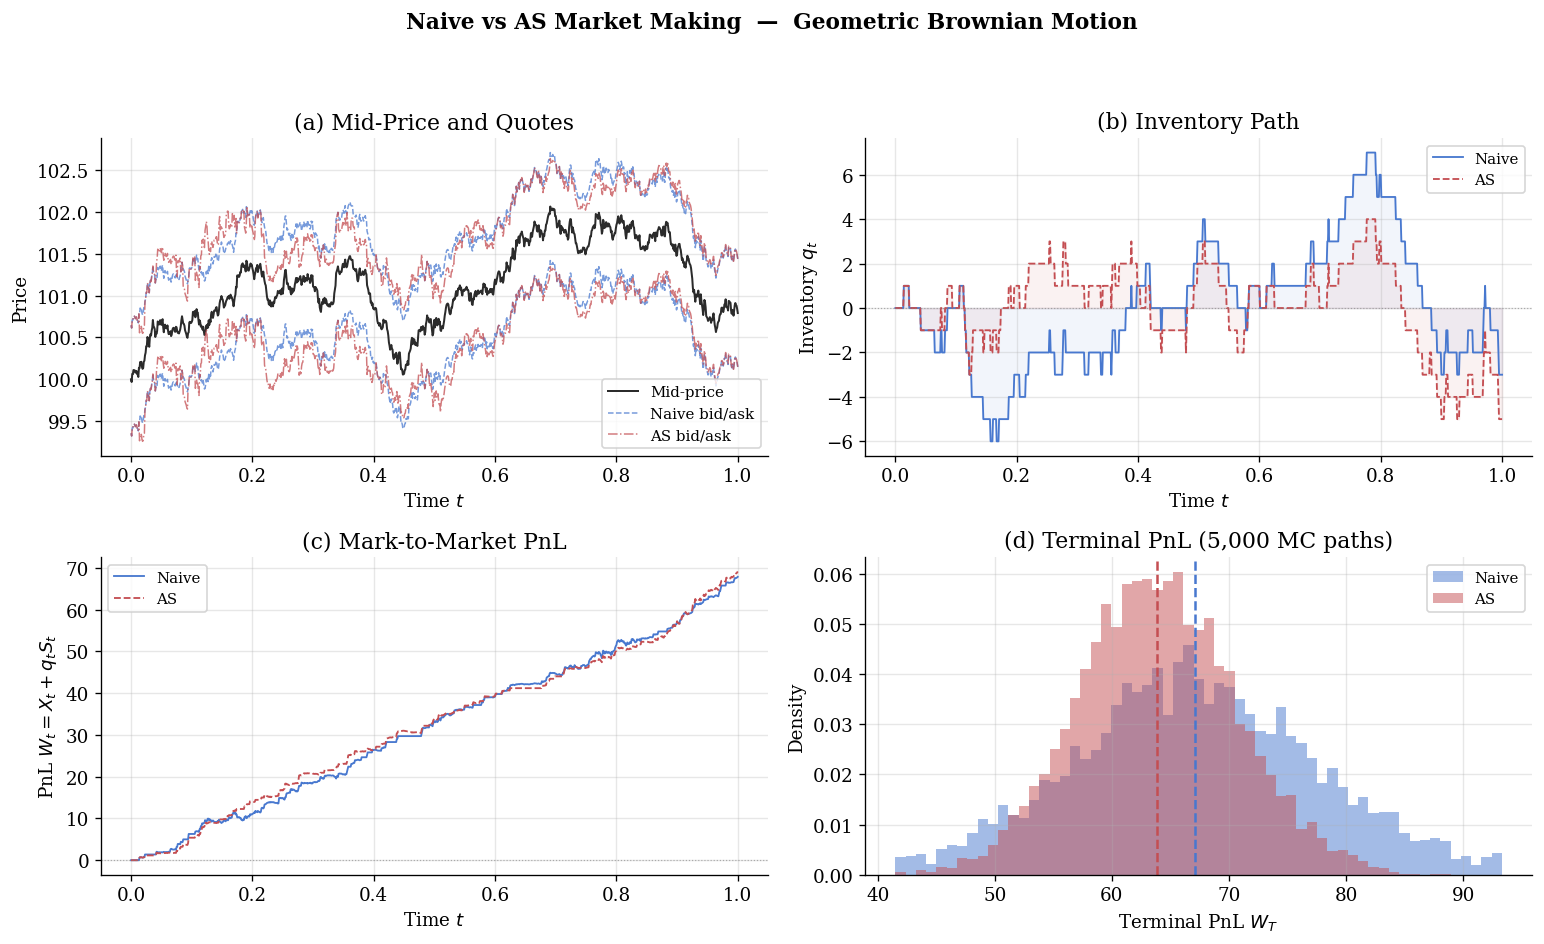

Saved: C:\Users\salvm\Desktop\SF\HFT\1\py2.png


In [17]:
fig2 = make_figure(t_arr, S_GBM, r_naive_GBM, r_as_GBM, mc_GBM,
                   label='Geometric Brownian Motion', filename='py2.png')

In [18]:
print('\n=== FINAL CHECK ===')
for fname in ['py1.png', 'py2.png']:
    full = os.path.join(OUTPUT_DIR, fname)
    ok   = os.path.isfile(full)
    size = os.path.getsize(full) if ok else 0
    print(f'  {fname}: {"OK" if ok else "MISSING"}  ({size:,} bytes)')


=== FINAL CHECK ===
  py1.png: OK  (310,339 bytes)
  py2.png: OK  (334,917 bytes)
